# Phase 25D -- BARRBenefitRouterV1 Training

**Method:** RA-MedFiLM-BARR  
**Router spec revision:** v1.2.1  
**Architecture:** ra_medfilm_barr_narrowed_v1_2  
**Seed:** 42

## 2. Predecessor terminal

```
PHASE25D_ROUTER_TRAINING_SPEC_V1_2_1_COMPLETE__CV_CHECKPOINT_TARGET_NORMALIZATION_AND_FINAL_REFIT_RULES_FROZEN__PHASE25D_REENTRY_ELIGIBLE_NOT_STARTED
```

## 3. Blocked-attempt provenance

First Phase25D entry blocked at `PHASE25D_BLOCKED__ROUTER_TRAINING_SPEC_INCOMPLETE`. Preserved in `reports/audits/phase25d_blocked_spec_incomplete.json`.

## 4. v1.2.1 exact training contract

- 5-fold outer CV: `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`
- Inner split: `StratifiedGroupKFold(n_splits=10, random_state=4200+k)`
- Checkpoint: lowest EARLY_STOP mean Huber loss
- Target: raw `delta_dice`, no scaling
- Normalization: 8 continuous scalars standardized on FIT only
- Final epoch: exact median of 5 best epochs
- Final refit: fresh seed=42, train-Huber scheduler monitor, last fixed epoch

## 5. Phase25B binding

- Features: `data_cache/phase25b_barr_pre_refinement_features_v1_2/` (4957 x 202)
- Notebook SHA: `acdfe90a...`

## 6. Phase25C binding

- Labels: `data_cache/phase25c_barr_oof_paired_gain_labels_v1_2/` (4957 rows)
- Label SHA: `fd6ca32c...`

## 7. Development population

```python
ROUTER_DEVELOPMENT = 4957
ROUTER_HOLDOUT = 875
```

## 8. Locks

- ROUTER_HOLDOUT: 0 reads
- VAL808: 0 reads
- TEST: LOCKED until Phase 39

## 9. CV5 frozen manifest

| fold | total | BUSI | ISIC | KUB | KVASIR |
|---|---|---|---|---|---|
| 0 | 992 | 103 | 434 | 337 | 118 |
| 1 | 992 | 103 | 435 | 335 | 119 |
| 2 | 991 | 102 | 435 | 336 | 118 |
| 3 | 991 | 102 | 435 | 336 | 118 |
| 4 | 991 | 102 | 434 | 336 | 119 |

## 10. Nested FIT/EARLY_STOP/OUTER_TARGET contract

Per fold: FIT ~90%, EARLY_STOP ~10%, OUTER_TARGET reserved for OOF only.

## 11. Architecture

`Embedding(4,16) -> Linear(218,128) -> LayerNorm(128) -> SiLU -> Dropout(0.10) -> Linear(128,64) -> LayerNorm(64) -> SiLU -> Dropout(0.10) -> Linear(64,1)`

## 12. Parameter arithmetic

**Total trainable = 36,801** (linear core 36,353 + embedding 64 + LayerNorm affine 384)

## 13. Implementation tests

All structural tests PASS. 36801 params exact.

## 14. Exact normalization

8 continuous scalars standardized on FIT only (population std, ddof=0).

## 15. Exact raw target

`raw delta_dice`, float32, **NO** scaling/centering/clipping.

## 16. Optimizer / loss / scheduler

- AdamW(lr=1e-3, wd=1e-4)
- Huber(delta=0.05, mean)
- ReduceLROnPlateau(mode=min, factor=0.5, patience=8, threshold=1e-4, min_lr=1e-6)

## 17. Fold 0 complete epoch table

Best epoch: **37** | Total epochs: 57 | Termination: early_stop

| epoch | train_huber | early_stop_huber | learning_rate | bad_epochs | is_best | elapsed_seconds |
|---|---|---|---|---|---|---|
| 1 | 0.0058137736299873465 | 0.0005339381750673056 | 0.001 | 0 | True | 0.34 |
| 2 | 0.0012858332109837128 | 8.123245788738132e-05 | 0.001 | 0 | True | 0.457 |
| 3 | 0.0006303495756583288 | 7.295709383470239e-05 | 0.001 | 0 | True | 0.58 |
| 4 | 0.00040576646279077977 | 6.0370544701982e-05 | 0.001 | 0 | True | 0.71 |
| 5 | 0.0003300550966482011 | 7.78828575676016e-05 | 0.001 | 1 | False | 0.82 |
| 6 | 0.00027604270560134737 | 6.211481763784832e-05 | 0.001 | 2 | False | 0.926 |
| 7 | 0.00022780108442280574 | 7.595386432512896e-05 | 0.001 | 3 | False | 1.045 |
| 8 | 0.0001962060845731425 | 6.231946872503613e-05 | 0.001 | 4 | False | 1.152 |
| 9 | 0.0001789948219084181 | 5.7104560141851834e-05 | 0.001 | 0 | True | 1.277 |
| 10 | 0.0001642413254947834 | 5.748040132402821e-05 | 0.001 | 1 | False | 1.387 |

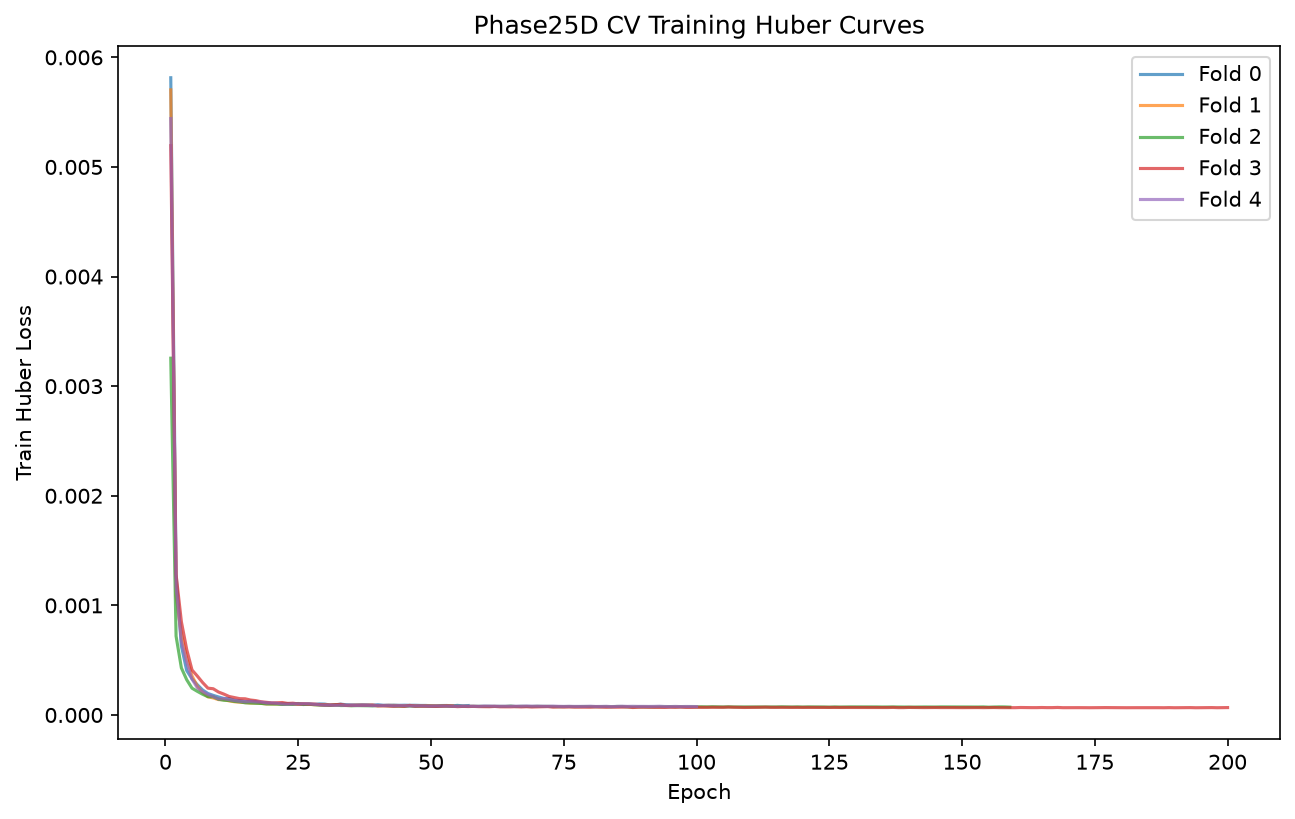

In [ ]:
# Fold 0 training curve

## 18. Fold 1 complete epoch table

Best epoch: **34** | Total epochs: 54 | Termination: early_stop

| epoch | train_huber | early_stop_huber | learning_rate | bad_epochs | is_best | elapsed_seconds |
|---|---|---|---|---|---|---|
| 1 | 0.005702981467558337 | 0.00037818292912561446 | 0.001 | 0 | True | 0.099 |
| 2 | 0.0010868489459556127 | 9.186728857457638e-05 | 0.001 | 0 | True | 0.246 |
| 3 | 0.0007375316074883033 | 5.783251799584832e-05 | 0.001 | 0 | True | 0.393 |
| 4 | 0.0005159556198382884 | 5.187147917240509e-05 | 0.001 | 0 | True | 0.525 |
| 5 | 0.0003573331975660819 | 4.959106604474073e-05 | 0.001 | 0 | True | 0.649 |
| 6 | 0.0002614805692116663 | 4.222701068101742e-05 | 0.001 | 0 | True | 0.761 |
| 7 | 0.00020399294641850117 | 4.639375526949152e-05 | 0.001 | 1 | False | 0.889 |
| 8 | 0.00016613143400588472 | 4.264913081897248e-05 | 0.001 | 2 | False | 0.984 |
| 9 | 0.0001553938706950118 | 3.998977263108827e-05 | 0.001 | 0 | True | 1.112 |
| 10 | 0.00014025685179928717 | 4.942536861562985e-05 | 0.001 | 1 | False | 1.208 |

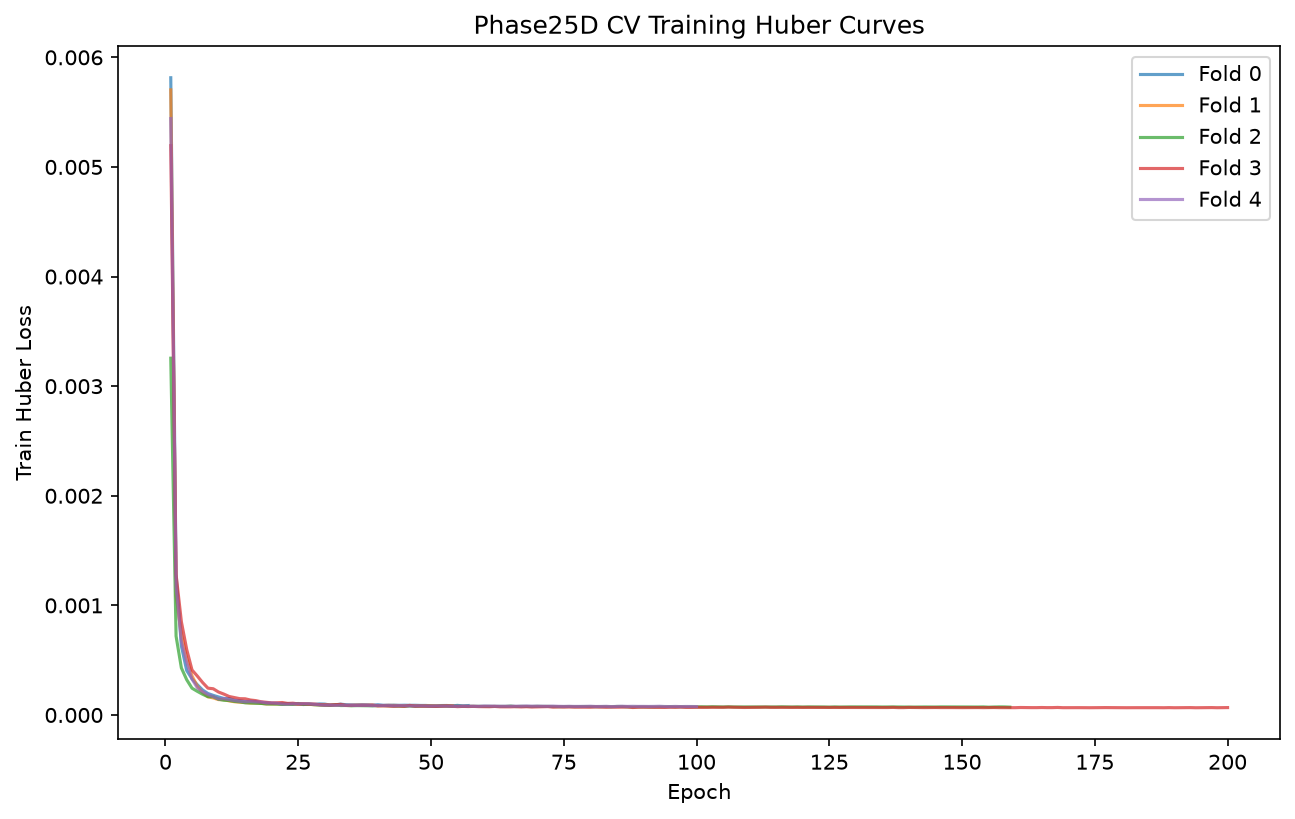

In [ ]:
# Fold 1 training curve

## 19. Fold 2 complete epoch table

Best epoch: **139** | Total epochs: 159 | Termination: early_stop

| epoch | train_huber | early_stop_huber | learning_rate | bad_epochs | is_best | elapsed_seconds |
|---|---|---|---|---|---|---|
| 1 | 0.003255218473246454 | 0.0006961231993045658 | 0.001 | 0 | True | 0.138 |
| 2 | 0.0007194442701542617 | 9.7348239251005e-05 | 0.001 | 0 | True | 0.272 |
| 3 | 0.000429172081307375 | 0.00014052547157916706 | 0.001 | 1 | False | 0.425 |
| 4 | 0.0003218408258232687 | 6.41935779412961e-05 | 0.001 | 0 | True | 0.559 |
| 5 | 0.0002445173200352916 | 6.11317208267792e-05 | 0.001 | 0 | True | 0.71 |
| 6 | 0.0002157556804637092 | 9.556037639413262e-05 | 0.001 | 1 | False | 0.842 |
| 7 | 0.0001890933667060121 | 6.260356735765527e-05 | 0.001 | 2 | False | 0.97 |
| 8 | 0.000166962844689676 | 6.871402638353175e-05 | 0.001 | 3 | False | 1.103 |
| 9 | 0.0001658056158443547 | 8.727194017410511e-05 | 0.001 | 4 | False | 1.214 |
| 10 | 0.00014369038711135675 | 7.149468342504406e-05 | 0.001 | 5 | False | 1.353 |

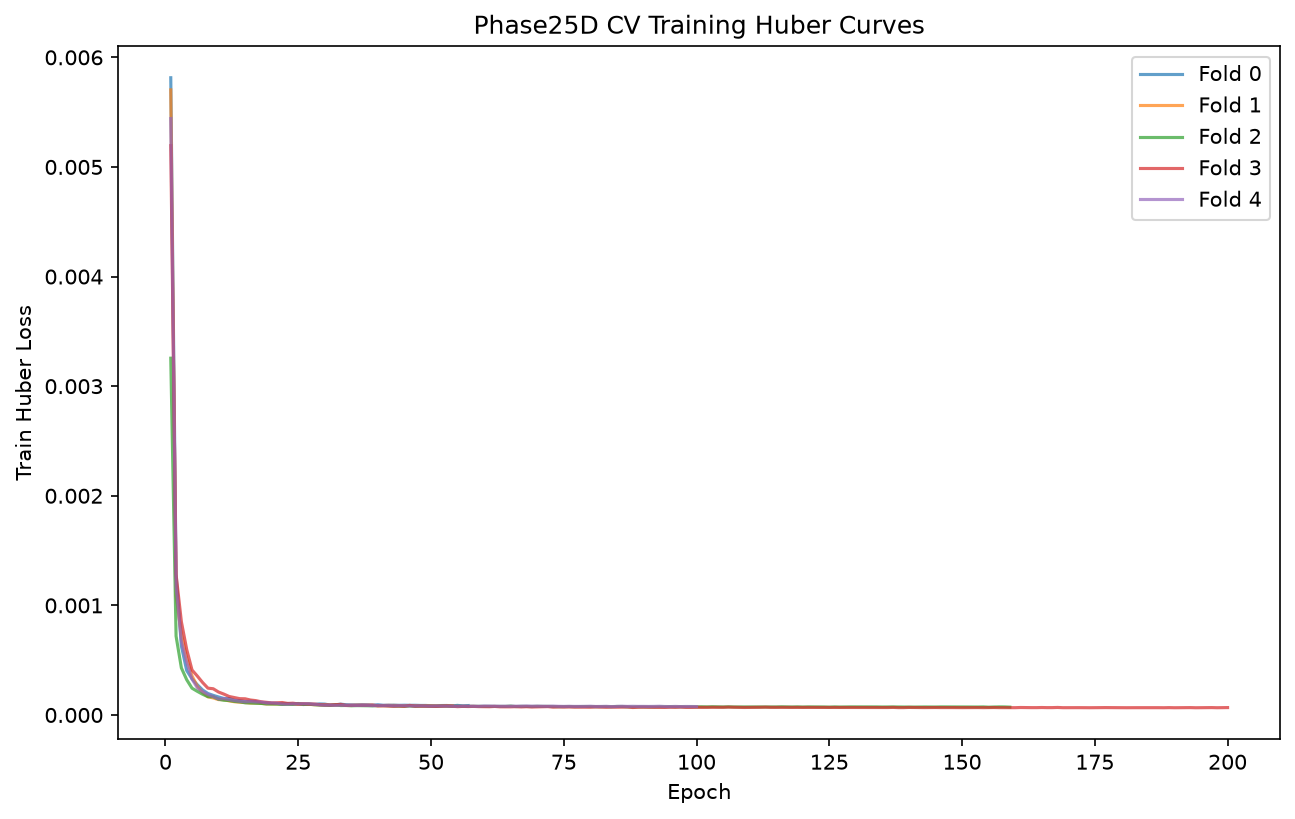

In [ ]:
# Fold 2 training curve

## 110. Fold 3 complete epoch table

Best epoch: **199** | Total epochs: 200 | Termination: max_epochs

| epoch | train_huber | early_stop_huber | learning_rate | bad_epochs | is_best | elapsed_seconds |
|---|---|---|---|---|---|---|
| 1 | 0.005194218920743359 | 0.00018263230231241323 | 0.001 | 0 | True | 0.105 |
| 2 | 0.0012816655861180542 | 0.00014355124039866496 | 0.001 | 0 | True | 0.224 |
| 3 | 0.0008506060735921242 | 8.35353166621644e-05 | 0.001 | 0 | True | 0.333 |
| 4 | 0.0005981914686604536 | 5.318152409472532e-05 | 0.001 | 0 | True | 0.443 |
| 5 | 0.00041081211384152994 | 7.288555866580282e-05 | 0.001 | 1 | False | 0.538 |
| 6 | 0.0003552229391061701 | 0.00011329240987834055 | 0.001 | 2 | False | 0.657 |
| 7 | 0.000295942640929882 | 5.447395847113512e-05 | 0.001 | 3 | False | 0.752 |
| 8 | 0.0002447532980503248 | 5.110480216785618e-05 | 0.001 | 0 | True | 0.886 |
| 9 | 0.00023936928898495222 | 5.6388377970506554e-05 | 0.001 | 1 | False | 0.977 |
| 10 | 0.0002092825281059569 | 7.007422800597851e-05 | 0.001 | 2 | False | 1.091 |

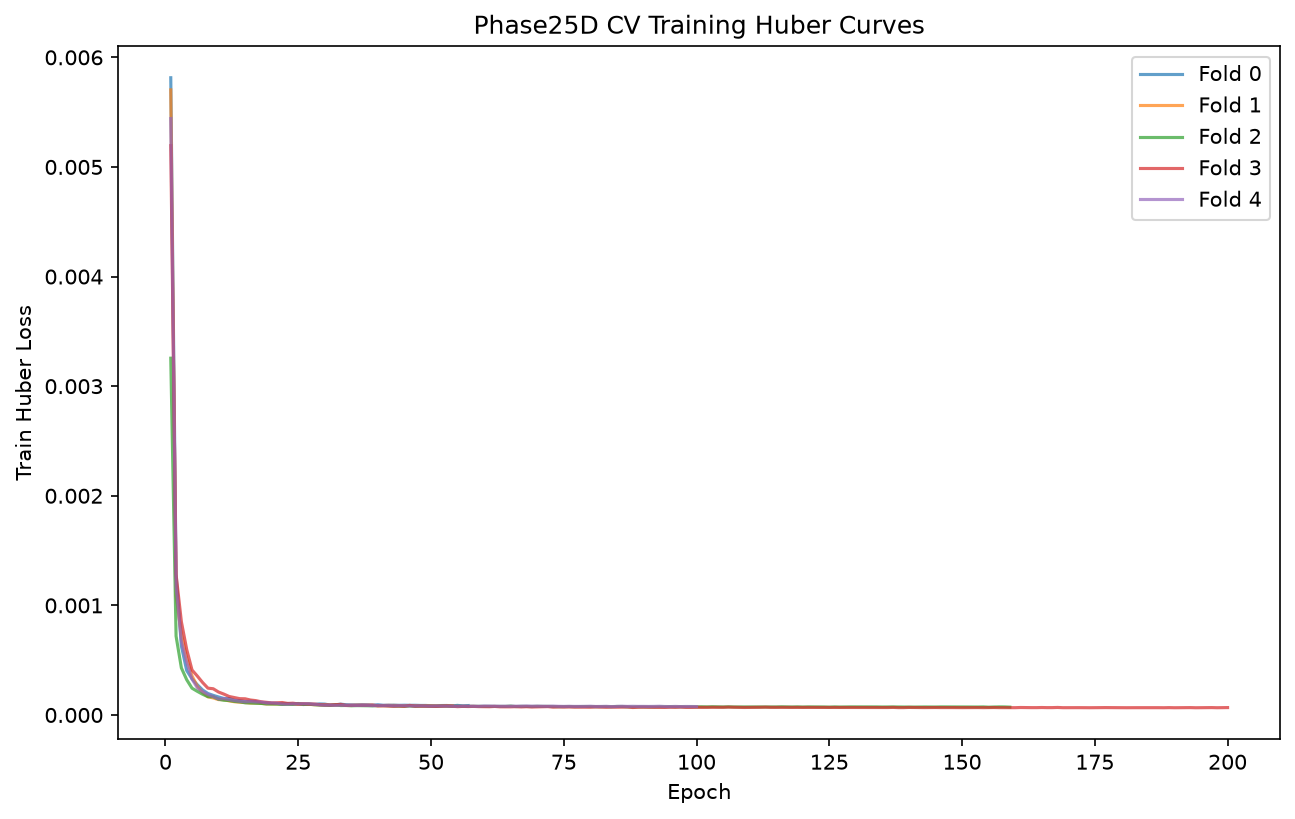

In [ ]:
# Fold 3 training curve

## 111. Fold 4 complete epoch table

Best epoch: **80** | Total epochs: 100 | Termination: early_stop

| epoch | train_huber | early_stop_huber | learning_rate | bad_epochs | is_best | elapsed_seconds |
|---|---|---|---|---|---|---|
| 1 | 0.005441325109651578 | 0.00039222275518113747 | 0.001 | 0 | True | 0.135 |
| 2 | 0.0011659391249330448 | 7.990294619730776e-05 | 0.001 | 0 | True | 0.285 |
| 3 | 0.000677240131023739 | 0.0001390024208376417 | 0.001 | 1 | False | 0.408 |
| 4 | 0.00047878220773002667 | 7.841556902121738e-05 | 0.001 | 0 | True | 0.563 |
| 5 | 0.00032771921697920855 | 7.761924970850487e-05 | 0.001 | 0 | True | 0.703 |
| 6 | 0.00024798491046697436 | 8.816140098133474e-05 | 0.001 | 1 | False | 0.826 |
| 7 | 0.00021291304074111395 | 7.811997852513741e-05 | 0.001 | 2 | False | 0.953 |
| 8 | 0.00018673099319650128 | 7.745208552023541e-05 | 0.001 | 0 | True | 1.09 |
| 9 | 0.00016774301340254688 | 7.709381375775592e-05 | 0.001 | 0 | True | 1.218 |
| 10 | 0.00014654395402301037 | 8.227286161854863e-05 | 0.001 | 1 | False | 1.324 |

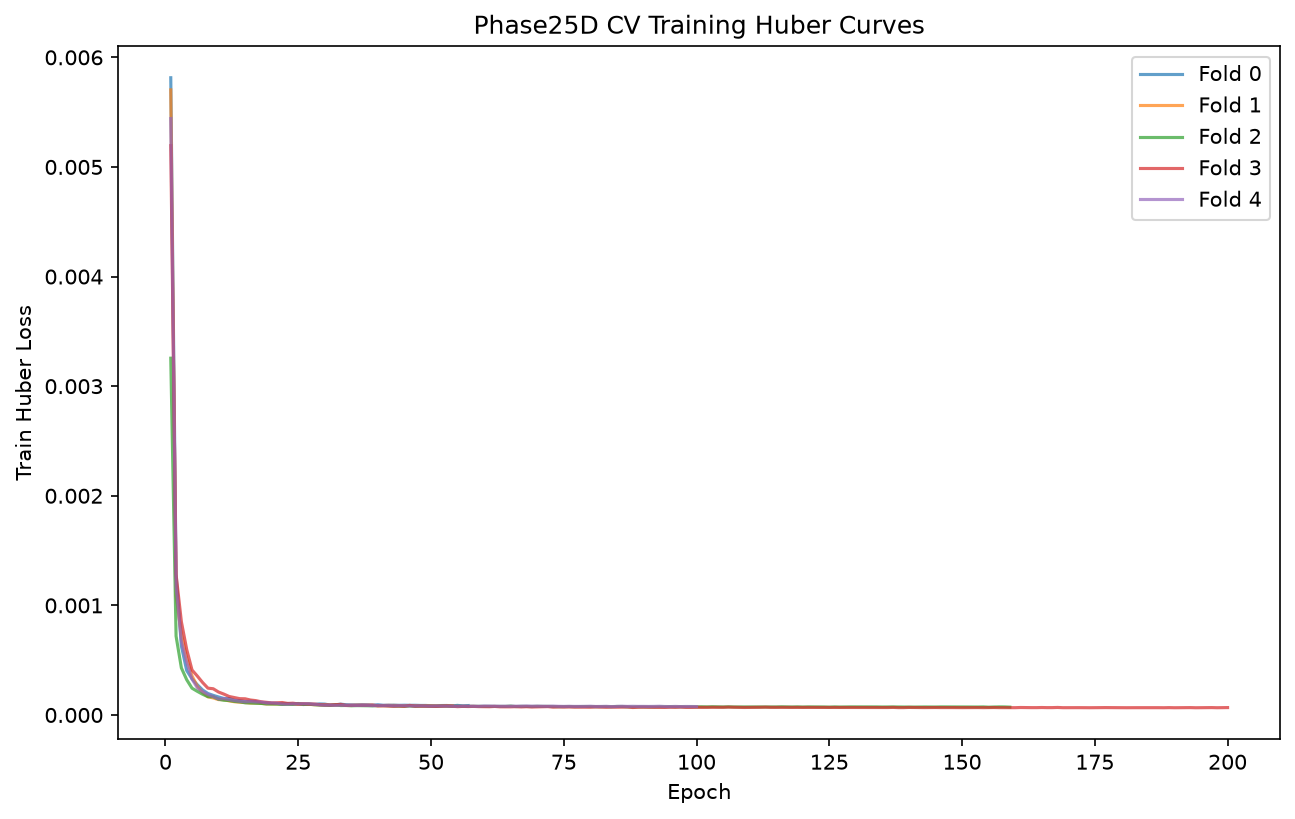

In [ ]:
# Fold 4 training curve

## 22. Five selected best epochs

| fold | best_epoch | best_es_huber | total_epochs | termination |
|---|---|---|---|---|
| 0 | 37 | 5.632870573890614e-05 | 57 | early_stop |
| 1 | 34 | 3.8186631741155e-05 | 54 | early_stop |
| 2 | 139 | 5.625082314963947e-05 | 159 | early_stop |
| 3 | 199 | 4.626554454034704e-05 | 200 | max_epochs |
| 4 | 80 | 7.360472127970752e-05 | 100 | early_stop |

## 23. OOF coverage

4957 rows, 0 missing, 0 duplicates, all finite.

## 24. OOF prediction integrity

All 4957 OOF predictions verified finite. Determinism audit PASS.

## 25. Predicted vs true DeltaDice

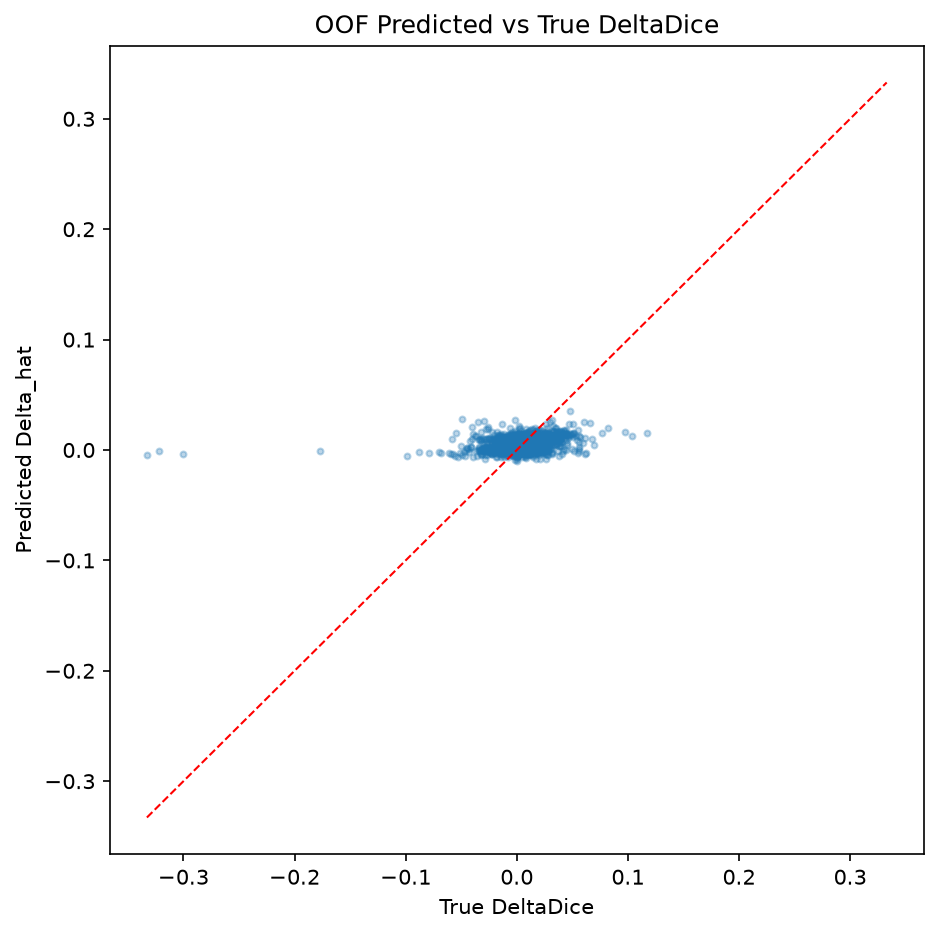

In [ ]:
# OOF scatter

## 26. Overall regression metrics

| metric | value |
|---|---|
| huber | 7.112138700904325e-05 |
| mae | 0.006642347667366266 |
| rmse | 0.013814026489853859 |
| pearson | 0.29962822794914246 |
| spearman | 0.21394063290695958 |
| r2 | 0.087657630443573 |

## 27. Per-domain metrics

| domain | huber | mae | rmse | pearson | spearman | r2 |
|---|---|---|---|---|---|---|
| KVASIR | 3.2185946565732593e-06 | 0.0015764139825478196 | 0.0025371615774929523 | -0.039820656180381775 | -0.008959769127033574 | -0.39362967014312744 |
| ISIC | 2.8332662623142824e-05 | 0.004764263518154621 | 0.007558337412774563 | 0.15809015929698944 | 0.13417320390692888 | 0.007339119911193848 |
| BUSI | 2.436577005937579e-06 | 0.001626220066100359 | 0.0022075222805142403 | 0.002840244211256504 | -0.008693698429864616 | -0.32928597927093506 |
| KUB | 0.00017132672655861825 | 0.012385420501232147 | 0.02203197218477726 | 0.3061244487762451 | 0.3188041796047271 | 0.09026294946670532 |

## 28. Per-fold metrics

| fold | huber | mae | rmse | pearson | spearman | r2 |
|---|---|---|---|---|---|---|
| fold0 | 7.373146218014881e-05 | 0.006942798383533955 | 0.012470555491745472 | 0.29495611786842346 | 0.15087166134141852 | 0.08381915092468262 |
| fold1 | 7.313333480851725e-05 | 0.006751617416739464 | 0.0148715665563941 | 0.3722846508026123 | 0.2635643358278358 | 0.11931735277175903 |
| fold2 | 6.312203913694248e-05 | 0.006408013869076967 | 0.011274347081780434 | 0.31516051292419434 | 0.230563989406907 | 0.09613895416259766 |
| fold3 | 8.643574255984277e-05 | 0.006659763865172863 | 0.017774563282728195 | 0.27766677737236023 | 0.28863660118418455 | 0.07614147663116455 |
| fold4 | 5.917968155699782e-05 | 0.006449128966778517 | 0.011593857780098915 | 0.27409857511520386 | 0.16098927330585666 | 0.052816808223724365 |

## 29. Residual analysis

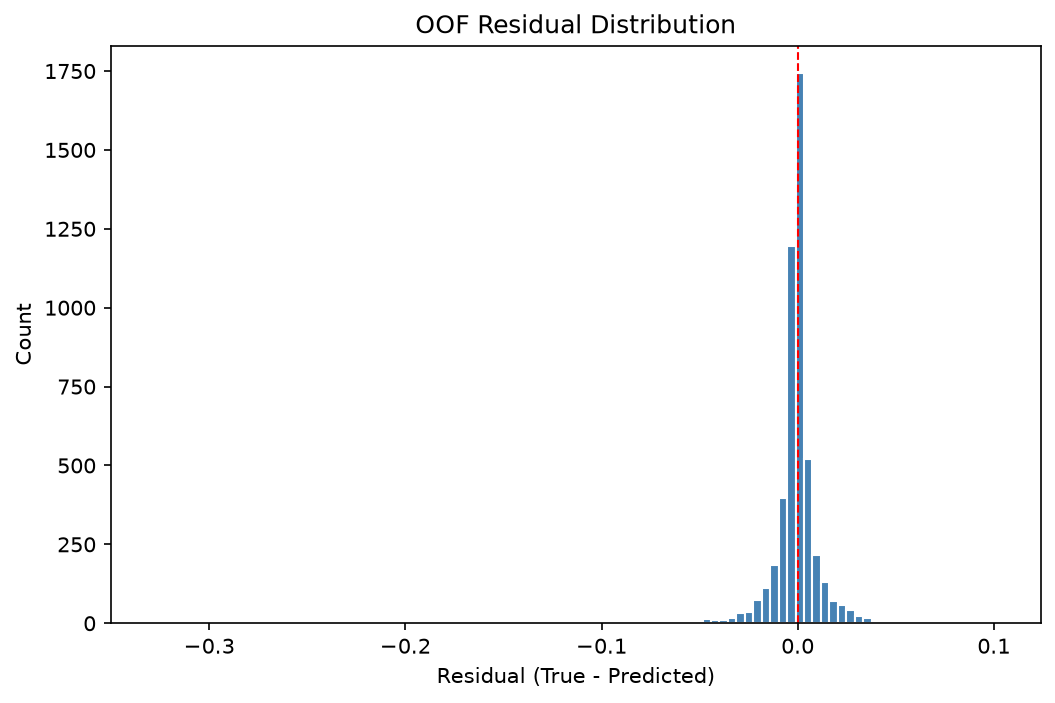

In [ ]:
# Residual distribution

## 30. Secondary beneficial discrimination

Classification: `SECONDARY_DESCRIPTIVE__NO_THRESHOLD_SELECTION`

| comparison | roc_auc | pr_auc |
|---|---|---|
| beneficial_vs_rest | 0.8137012174308795 | 0.3487565890819809 |
| harmful_vs_rest | 0.5319871865251845 | 0.09651033297792833 |

## 31. Secondary harmful discrimination

(Same table as above -- no threshold selected.)

## 32. Interpretation discipline

Phase25C shows strongly heterogeneous paired refinement gain. Most samples neutral, both beneficial and harmful cases exist. Aggregate behaviour belongs to Phase22.

## 33. Exact median final-epoch rule

Best epochs: [37, 34, 139, 199, 80]
Sorted: [34, 37, 80, 139, 199]
**FINAL_ROUTER_EPOCHS = 80**

## 34. Final normalization

Fitted on ALL 4957 DEV rows. Persisted in final checkpoint.

## 35. Final refit complete epoch table

| epoch | train_huber | learning_rate | elapsed_seconds |
|---|---|---|---|
| 1 | 0.0036791132267516777 | 0.001 | 0.167 |
| 2 | 0.0006087743915999547 | 0.001 | 0.311 |
| 3 | 0.0003588328664847769 | 0.001 | 0.479 |
| 4 | 0.0002574537338193458 | 0.001 | 0.624 |
| 5 | 0.00019210353769803754 | 0.001 | 0.781 |
| 6 | 0.0001675256536169073 | 0.001 | 0.941 |
| 7 | 0.00015160064392078383 | 0.001 | 1.086 |
| 8 | 0.0001426081642141351 | 0.001 | 1.227 |
| 9 | 0.00012668336775953858 | 0.001 | 1.378 |
| 10 | 0.00012090208549171877 | 0.001 | 1.511 |
| 11 | 0.00011881094206518565 | 0.001 | 1.662 |
| 12 | 0.00011275695709254927 | 0.001 | 1.811 |
| 13 | 0.00011140939713163205 | 0.001 | 1.977 |
| 14 | 0.00010995455672039102 | 0.001 | 2.139 |
| 15 | 0.00010329576821860451 | 0.001 | 2.273 |

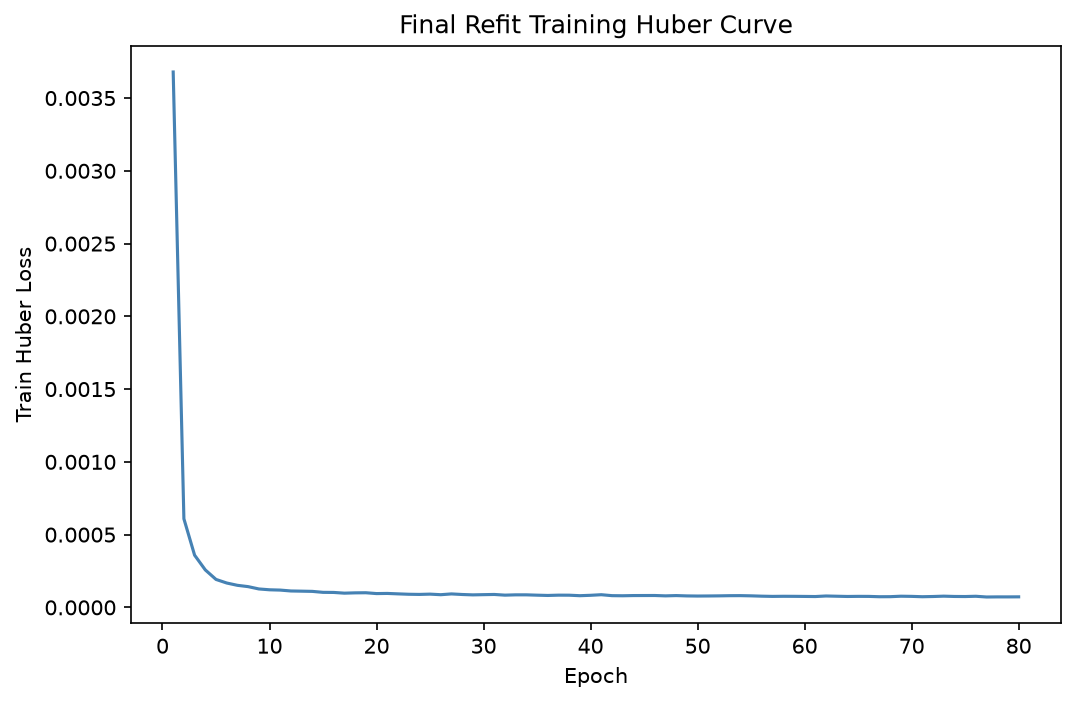

In [ ]:
# Final refit curve

## 36. Final checkpoint

`checkpoints/phase25d_barr_benefit_router_v1_2_1_seed42/final/final.pt`

- Parameter count: 36801
- State dict load: PASS
- Synthetic inference: PASS

## 37. Compute bookkeeping

Router Linear MACs per sample: ~31k (218x128 + 128x64 + 64x1).

## 38. No lambda assertion

**lambda NOT selected.** Phase25D does not execute resource-gate calibration.

## 39. No gate-threshold assertion

**Routing threshold NOT calibrated.**

## 40. No holdout assertion

**ROUTER_HOLDOUT reads = 0.**

## 41. No VAL808 assertion

**VAL808 reads = 0.**

## 42. No TEST assertion

**TEST reads = 0.**

## 43. Phase25E handoff

Phase25D provides: final checkpoint, normalization stats, task registry, 4957 OOF predictions, paired labels, feature schema, CV provenance.

Phase25E owns: resource cost C, lambda grid, U_hat, activation gate, budget analysis, threshold semantics.

## 44. Final assertions

- Reentry gate: PASS
- Architecture: 36801 params exact
- 5 CV runs complete
- OOF: 4957 rows, all finite
- Final refit: 80 epochs fixed
- Notebook: 0 errors
- Test reads: 0
- Phase25E: NOT started